# Focused final data pass

**Review date: 5 November 2026.** The written findings are a snapshot of the supplied files. If the files change, rerun the checks and refresh the written findings before relying on the old counts.

This notebook checks the remaining practical risks before database and playback decisions. It is a new, independent pass; `exp.ipynb` contains the earlier exploration and combat investigation.

**Read the explanation before each check, then its labelled output, then “What we found.”** We distinguish a measured fact, an uncertain explanation, and a proposed handling decision.

**Source of truth:** all supplied files and their original rows. We do not edit them. We compare alternative counting policies only to measure their effects; no policy is silently applied to the application.

**Three different data views are named explicitly:**

- **All supplied rows:** every file is included.
- **One copy per identical file:** for a diagnostic comparison, keep the alphabetically first path for each file hash. Keep the original inventory so both source paths remain visible.
- **One copy per identical payload:** a separate diagnostic comparison of the eight source fields. This is not an approved cleanup policy, because repeated pickups may be legitimate events.

**Scope of the pass:** structural quality; copied files and repeated rows; event keys and dates; movement gaps and large jumps; independent counts for three matches; map assets and coordinate conversion; and a concise recheck of the combat investigation's separate scopes.

**Run:** select the project's `.venv` kernel and run all cells, or use `.venv/bin/python "rough work/scripts/execute_notebook.py" focused_final_pass.ipynb`. Java 17+ and localhost sockets are needed for Spark. All event-level analysis uses Spark; PyArrow inspects source files and independently counts a few selected matches. Small summaries use pandas and Matplotlib.

References: `player_data/README.md`, `docs/PRODUCT_BRIEF.md`, `docs/reference/lila-product-engineer-written-test.txt`, and `docs/DATA_AUDIT.md`. The consolidated report will be `docs/DATA_NUANCES.md`.

> **Current project decisions — 5 November 2026**
>
> The original four concerns are handled: use seconds after checking all 796 spans, credit kill labels to the recorded actor, count every Loot row as one item, and plot the supplied recordings.
>
> Four additional handling rules are now accepted: keep the first whole-file copy, advance playback directly between recorded timestamps, plot all positions including post-death updates, and partition/filter processed records by timestamp date (UTC working convention).
>
> **Only repeated combat-row counting remains undecided.** Historical diagnostic comparisons below do not override these rules. The source files and executed code outputs are preserved; this update records decisions rather than performing an ETL import. The final project document must explain each nuance and how it was handled, especially the post-death position updates.

## 1. Start the pass

**What we are checking:** We need the supplied files, a reproducible Spark session, and a place for derived evidence.

**What we will print:** The Python and Spark versions, dataset location, and number of files found.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as parquet
from PIL import Image
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from IPython.display import display

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable

project_folder = Path.cwd().resolve()
while not (project_folder / "player_data").is_dir():
    if project_folder == project_folder.parent:
        raise FileNotFoundError("Open this notebook inside the LILA games project folder.")
    project_folder = project_folder.parent
data_folder = project_folder / "player_data"
evidence_folder = project_folder / "rough work" / "analysis" / "focused_final_pass"
evidence_folder.mkdir(parents=True, exist_ok=True)
parquet_files = sorted(data_folder.glob("February_*/*.nakama-0"))
if not parquet_files:
    raise FileNotFoundError("Run from the project folder containing player_data.")

spark = (
    SparkSession.builder.master("local[2]")
    .appName("LILA focused final pass")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
facts = {}
print("Python:", sys.version.split()[0])
print("Spark:", spark.version)
print("Data folder:", data_folder)
print("Supplied Parquet files:", len(parquet_files))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/05 14:27:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Python: 3.14.4
Spark: 4.3.0
Data folder: /Users/mskbaruah/Documents/ChatGPT/LILA games/player_data
Supplied Parquet files: 1243


## 2. Check every file and keep its provenance

**What we are checking:** A repeated file can repeat many events. We also need to know whether all files are readable, share a schema, and arrive in chronological row order.

**What we will print:** File counts by folder, read failures, schema count, source timestamp-order exceptions, and groups of byte-identical files.

In [2]:
file_records = []
read_failures = []
for file_path in parquet_files:
    try:
        source = parquet.ParquetFile(file_path)
        original_times = source.read(columns=["ts"])["ts"].cast(pa.int64()).to_pylist()
        backwards_steps = 0
        for index in range(1, len(original_times)):
            if original_times[index] is not None and original_times[index - 1] is not None:
                if original_times[index] < original_times[index - 1]:
                    backwards_steps += 1
        file_records.append({
            "source_file": str(file_path.relative_to(data_folder)),
            "collection_folder": file_path.parent.name,
            "file_hash": hashlib.sha256(file_path.read_bytes()).hexdigest(),
            "source_rows": source.metadata.num_rows,
            "file_bytes": file_path.stat().st_size,
            "row_groups": source.metadata.num_row_groups,
            "schema": str(source.schema_arrow.remove_metadata()),
            "backwards_steps": backwards_steps,
        })
    except Exception as error:
        read_failures.append({"source_file": str(file_path), "error": str(error)})

file_inventory = pd.DataFrame(file_records)
print("File read failures; an empty table means no failures:")
display(pd.DataFrame(read_failures, columns=["source_file", "error"]))
if read_failures:
    raise RuntimeError("Fix unreadable files before continuing the full-data pass.")

print("Supplied files, rows, and physical bytes in each folder:")
display(file_inventory.groupby("collection_folder").agg(
    files=("source_file", "count"), rows=("source_rows", "sum"), bytes=("file_bytes", "sum")
))
print("Distinct source schemas:", file_inventory["schema"].nunique())
print("Files with at least one timestamp going backwards:")
display(file_inventory.loc[file_inventory["backwards_steps"] > 0, ["source_file", "backwards_steps"]])

File read failures; an empty table means no failures:


,source_file,error


Supplied files, rows, and physical bytes in each folder:


,files,rows,bytes
collection_folder,,,
February_10,437,33687,2991430
February_11,293,21235,1992563
February_12,268,18429,1783860
February_13,166,11106,1103813
February_14,79,4647,499545


Distinct source schemas: 1
Files with at least one timestamp going backwards:


,source_file,backwards_steps
231,February_10/688cb2e4-2215-4b3b-9af1-a6ee71d176...,1
304,February_10/94d042cb-a0f2-45f3-bdca-42fab73cfe...,1
695,February_11/db454a35-d216-4379-b140-2931160c7d...,1


In [3]:
print("Byte-identical file groups; each group has the same SHA-256:")
identical_files = file_inventory[file_inventory.duplicated("file_hash", keep=False)]
display(identical_files[["source_file", "file_hash", "source_rows"]])

# The comparison policy is deterministic; it does not choose the true event date.
first_path_per_hash = file_inventory.groupby("file_hash")["source_file"].min()
last_path_per_hash = file_inventory.groupby("file_hash")["source_file"].max()
first_file_paths = set(first_path_per_hash.tolist())
last_file_paths = set(last_path_per_hash.tolist())
file_inventory["kept_in_first_path_comparison"] = file_inventory["source_file"].isin(first_file_paths)
file_inventory["kept_in_last_path_comparison"] = file_inventory["source_file"].isin(last_file_paths)

extra_file_rows = int(file_inventory.loc[
    ~file_inventory["kept_in_first_path_comparison"], "source_rows"
].sum())
facts["files"] = {
    "supplied_files": len(file_inventory),
    "supplied_rows": int(file_inventory["source_rows"].sum()),
    "bytes": int(file_inventory["file_bytes"].sum()),
    "schemas": int(file_inventory["schema"].nunique()),
    "read_failures": len(read_failures),
    "files_needing_sorting": int((file_inventory["backwards_steps"] > 0).sum()),
    "identical_file_groups": int(identical_files["file_hash"].nunique()),
    "extra_copied_file_rows": extra_file_rows,
}
file_inventory.to_csv(evidence_folder / "file_inventory.csv", index=False)
print("Rows repeated through an extra byte-identical file copy:", extra_file_rows)
print("The file inventory preserves both paths; this comparison has not deleted anything.")

Byte-identical file groups; each group has the same SHA-256:


,source_file,file_hash,source_rows
377,February_10/cfa03e9f-81f6-41ef-a0fa-30c7e830f4...,656dc648afa39cc591326c5db3845e6f50c4ce19423a52...,88
691,February_11/cfa03e9f-81f6-41ef-a0fa-30c7e830f4...,656dc648afa39cc591326c5db3845e6f50c4ce19423a52...,88


Rows repeated through an extra byte-identical file copy: 88
The file inventory preserves both paths; this comparison has not deleted anything.


**What we found**

All **1,243 files** were readable and shared one source schema. **Three files** contain a timestamp that goes backwards in original row order; replay must sort by time.

We confirmed **one byte-identical 88-row file** under both February 10 and February 11. It has the same filename, hash, and contents. This is a copied source recording, not two independent journeys. Its presence in two folders is not evidence that its events happened on two days. Both source paths remain in the saved inventory.

## 3. Load the data and repeat the structural quality checks

**What we are checking:** The next checks need readable event labels, stable source paths, raw time values, and reliable actor classification. Passing these checks does not settle event meanings.

**What we will print:** The original schema, total rows, null and nonfinite counts, UTF-8 round-trip failures, unknown values, and filename/record disagreements.

In [4]:
raw_events = (
    spark.read.option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*.nakama-0")
    .option("mergeSchema", "true")
    .parquet(str(data_folder))
)
print("Original Spark schema before interpretation:")
raw_events.printSchema()

events = raw_events.withColumn("source_location", F.input_file_name())
events = events.withColumn("source_file", F.regexp_extract("source_location", r"player_data/(.*)$", 1))
events = events.withColumn("source_filename", F.regexp_extract("source_file", r"([^/]+)$", 1))
events = events.withColumn("collection_day", F.regexp_extract("source_file", r"February_(\d+)", 1))
events = events.withColumn("collection_date", F.to_date(
    F.concat(F.lit("2026-02-"), F.col("collection_day")), "yyyy-MM-dd"
))
events = events.withColumnRenamed("event", "event_bytes")
events = events.withColumn("event", F.decode("event_bytes", "UTF-8"))
events = events.withColumn("timestamp_value", F.unix_millis("ts"))
uuid_pattern = (
    r"^[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-"
    r"[0-9a-fA-F]{4}-[0-9a-fA-F]{12}$"
)
events = events.withColumn("actor_type",
    F.when(F.col("user_id").rlike(r"^\d+$"), "bot")
    .when(F.col("user_id").rlike(uuid_pattern), "human")
    .otherwise("unknown")
).cache()
raw_row_count = events.count()
assert raw_row_count == facts["files"]["supplied_rows"]
print("Rows loaded, with every supplied file included:", raw_row_count)
print("Decoded labels and raw integer timestamps from five source records:")
events.select("user_id", "event_bytes", "event", "ts", "timestamp_value").show(5, truncate=False)

Original Spark schema before interpretation:
root
 |-- user_id: string (nullable = true)
 |-- match_id: string (nullable = true)
 |-- map_id: string (nullable = true)
 |-- x: float (nullable = true)
 |-- y: float (nullable = true)
 |-- z: float (nullable = true)
 |-- ts: timestamp_ntz (nullable = true)
 |-- event: binary (nullable = true)



Rows loaded, with every supplied file included: 89104
Decoded labels and raw integer timestamps from five source records:
+------------------------------------+-------------------------+--------+-----------------------+---------------+
|user_id                             |event_bytes              |event   |ts                     |timestamp_value|
+------------------------------------+-------------------------+--------+-----------------------+---------------+
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|[50 6F 73 69 74 69 6F 6E]|Position|1970-01-21 11:52:02.175|1770722175     |
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|[50 6F 73 69 74 69 6F 6E]|Position|1970-01-21 11:52:02.205|1770722205     |
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|[50 6F 73 69 74 69 6F 6E]|Position|1970-01-21 11:52:02.21 |1770722210     |
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|[50 6F 73 69 74 69 6F 6E]|Position|1970-01-21 11:52:02.215|1770722215     |
|94d042cb-a0f2-45f3-bdca-42fab73cfef5|[50 6F 73 69 74 69 6F 6E]|Position|1970-01

In [5]:
required_columns = ["user_id", "match_id", "map_id", "x", "y", "z", "ts", "event", "collection_date"]
null_checks = []
for column_name in required_columns:
    null_checks.append(F.sum(F.when(F.col(column_name).isNull(), 1).otherwise(0)).alias(column_name))
null_result = events.agg(*null_checks)
print("Missing values in each required field:")
null_result.show()

coordinate_checks = []
for column_name in ["x", "y", "z"]:
    value = F.col(column_name)
    invalid = F.isnan(value) | (F.abs(value) == float("inf"))
    coordinate_checks.append(F.sum(F.when(invalid, 1).otherwise(0)).alias(column_name))
coordinate_result = events.agg(*coordinate_checks)
print("NaN or infinite coordinate counts:")
coordinate_result.show()

known_events = ["Position", "BotPosition", "Kill", "Killed", "BotKill", "BotKilled", "KilledByStorm", "Loot"]
known_maps = ["AmbroseValley", "GrandRift", "Lockdown"]
filename_user = F.split("source_filename", "_").getItem(0)
filename_match = F.split("source_filename", "_").getItem(1)
identity_checks = events.agg(
    F.sum(F.when(F.encode("event", "UTF-8") != F.col("event_bytes"), 1).otherwise(0)).alias("utf8_roundtrip_failures"),
    F.sum(F.when(~F.col("event").isin(known_events), 1).otherwise(0)).alias("unknown_event_rows"),
    F.sum(F.when(~F.col("map_id").isin(known_maps), 1).otherwise(0)).alias("unknown_map_rows"),
    F.sum(F.when(F.col("actor_type") == "unknown", 1).otherwise(0)).alias("unknown_actor_rows"),
    F.sum(F.when(F.col("user_id") != filename_user, 1).otherwise(0)).alias("filename_user_mismatches"),
    F.sum(F.when(F.col("match_id") != filename_match, 1).otherwise(0)).alias("filename_match_mismatches"),
)
print("Encoding, expected-value, and source-identity checks:")
identity_checks.show(truncate=False)
facts["quality"] = {
    "null_counts": null_result.first().asDict(),
    "nonfinite_coordinates": coordinate_result.first().asDict(),
    "identity_and_encoding": identity_checks.first().asDict(),
}
print("A zero is a passing check, not proof that undocumented gameplay meanings are correct.")

Missing values in each required field:


+-------+--------+------+---+---+---+---+-----+---------------+
|user_id|match_id|map_id|  x|  y|  z| ts|event|collection_date|
+-------+--------+------+---+---+---+---+-----+---------------+
|      0|       0|     0|  0|  0|  0|  0|    0|              0|
+-------+--------+------+---+---+---+---+-----+---------------+

NaN or infinite coordinate counts:
+---+---+---+
|  x|  y|  z|
+---+---+---+
|  0|  0|  0|
+---+---+---+



Encoding, expected-value, and source-identity checks:


+-----------------------+------------------+----------------+------------------+------------------------+-------------------------+
|utf8_roundtrip_failures|unknown_event_rows|unknown_map_rows|unknown_actor_rows|filename_user_mismatches|filename_match_mismatches|
+-----------------------+------------------+----------------+------------------+------------------------+-------------------------+
|0                      |0                 |0               |0                 |0                       |0                        |
+-----------------------+------------------+----------------+------------------+------------------------+-------------------------+



A zero is a passing check, not proof that undocumented gameplay meanings are correct.


**What we found**

The pass loaded all **89,104 source rows**. All printed null, nonfinite-coordinate, unknown-value, filename-ID, and UTF-8 round-trip failure counts are **zero**.

These are structural passes. They do not prove that a combat label has the meaning we assume or that the timestamp unit in the schema is correct. The event field really is binary and needs decoding; the files really are Parquet despite the `.nakama-0` suffix.

## 4. Separate copied files from repeated event payloads

**What we are checking:** Known byte-identical files and ambiguous repeated pickups need different treatment. We quantify counting changes without approving a cleanup policy.

**What we will print:** Totals and event counts for three diagnostic policies; repeated payloads by event; and the effect of choosing the earlier or later source path on date counts.

In [6]:
# Keep the comparison path list small; Spark still processes all event rows.
first_path_table = spark.createDataFrame([(path,) for path in sorted(first_file_paths)], ["source_file"])
last_path_table = spark.createDataFrame([(path,) for path in sorted(last_file_paths)], ["source_file"])
one_copy_events = events.join(first_path_table, on="source_file", how="inner").cache()
last_path_events = events.join(last_path_table, on="source_file", how="inner")

payload_columns = ["match_id", "user_id", "map_id", "event", "timestamp_value", "x", "y", "z"]
one_payload_events = events.select(payload_columns).distinct().cache()
file_copy_row_count = one_copy_events.count()
payload_row_count = one_payload_events.count()

policy_totals = pd.DataFrame([
    {"comparison": "All supplied rows", "rows": raw_row_count},
    {"comparison": "One copy per identical file", "rows": file_copy_row_count},
    {"comparison": "One copy per identical payload", "rows": payload_row_count},
])
print("Diagnostic row totals; these are alternative counts, not three additive categories:")
display(policy_totals)

raw_event_counts = events.groupBy("event").count().withColumnRenamed("count", "all_supplied_rows")
file_event_counts = one_copy_events.groupBy("event").count().withColumnRenamed("count", "one_copy_per_file")
payload_event_counts = one_payload_events.groupBy("event").count().withColumnRenamed("count", "one_copy_per_payload")
policy_event_counts = raw_event_counts.join(file_event_counts, "event").join(payload_event_counts, "event")
print("How each counting policy affects each recorded event label:")
policy_event_counts.orderBy("event").show(truncate=False)
policy_event_counts.toPandas().to_csv(evidence_folder / "duplicate_policy_event_counts.csv", index=False)

raw_payload_groups = events.groupBy(payload_columns).agg(
    F.count("*").alias("copies"), F.countDistinct("source_file").alias("source_files")
).filter(F.col("copies") > 1)
remaining_payload_groups = one_copy_events.groupBy(payload_columns).count().filter(F.col("count") > 1)
remaining_by_event = remaining_payload_groups.groupBy("event").agg(
    F.count("*").alias("repeated_payload_groups"),
    F.sum(F.col("count") - 1).alias("extra_rows"),
    F.max("count").alias("largest_number_of_copies"),
)
print("Payload repetition remaining after excluding only the extra identical-file copy:")
remaining_by_event.orderBy("event").show(truncate=False)

Diagnostic row totals; these are alternative counts, not three additive categories:


,comparison,rows
0,All supplied rows,89104
1,One copy per identical file,89016
2,One copy per identical payload,87599


How each counting policy affects each recorded event label:


+-------------+-----------------+-----------------+--------------------+
|event        |all_supplied_rows|one_copy_per_file|one_copy_per_payload|
+-------------+-----------------+-----------------+--------------------+
|BotKill      |2415             |2410             |2376                |
|BotKilled    |700              |699              |697                 |
|BotPosition  |21712            |21712            |21712               |
|Kill         |3                |3                |3                   |
|Killed       |3                |3                |3                   |
|KilledByStorm|39               |39               |39                  |
|Loot         |12885            |12866            |11632               |
|Position     |51347            |51284            |51137               |
+-------------+-----------------+-----------------+--------------------+



Payload repetition remaining after excluding only the extra identical-file copy:


+---------+-----------------------+----------+------------------------+
|event    |repeated_payload_groups|extra_rows|largest_number_of_copies|
+---------+-----------------------+----------+------------------------+
|BotKill  |31                     |34        |3                       |
|BotKilled|2                      |2         |2                       |
|Loot     |1098                   |1234      |7                       |
|Position |147                    |147       |2                       |
+---------+-----------------------+----------+------------------------+



In [7]:
print("Collection-date counts under first-path versus last-path copied-file policies:")
first_dates = one_copy_events.groupBy("collection_date").count().withColumnRenamed("count", "keep_first_path")
last_dates = last_path_events.groupBy("collection_date").count().withColumnRenamed("count", "keep_last_path")
first_dates.join(last_dates, "collection_date").orderBy("collection_date").show()

print("One repeated payload after file-copy exclusion; multiple pickups may lack item-level distinctions:")
repeated_example = remaining_payload_groups.orderBy(F.desc("count"), "match_id", "timestamp_value").first()
if repeated_example is not None:
    repeated_match = repeated_example["match_id"]
    repeated_user = repeated_example["user_id"]
    repeated_time = repeated_example["timestamp_value"]
    one_copy_events.filter(
        (F.col("match_id") == repeated_match)
        & (F.col("user_id") == repeated_user)
        & (F.col("timestamp_value") == repeated_time)
    ).select("source_file", "user_id", "event", "timestamp_value", "x", "y", "z").show(15, truncate=False)

remaining_extra = remaining_payload_groups.agg(F.sum(F.col("count") - 1).alias("extra")).first()["extra"]
facts["duplicates"] = {
    "raw_rows": raw_row_count,
    "one_copy_per_file_rows": file_copy_row_count,
    "one_copy_per_payload_rows": payload_row_count,
    "raw_repeated_payload_groups": raw_payload_groups.count(),
    "raw_extra_payload_rows": raw_row_count - payload_row_count,
    "extra_rows_from_copied_file": raw_row_count - file_copy_row_count,
    "remaining_extra_payload_rows": int(remaining_extra or 0),
    "remaining_repeated_groups": remaining_payload_groups.count(),
    "remaining_repetition_by_event": [row.asDict() for row in remaining_by_event.orderBy("event").collect()],
}
print("The copied-file contribution is already included in the raw repeated-row total; do not add it again.")

Collection-date counts under first-path versus last-path copied-file policies:


+---------------+---------------+--------------+
|collection_date|keep_first_path|keep_last_path|
+---------------+---------------+--------------+
|     2026-02-10|          33687|         33599|
|     2026-02-11|          21147|         21235|
|     2026-02-12|          18429|         18429|
|     2026-02-13|          11106|         11106|
|     2026-02-14|           4647|          4647|
+---------------+---------------+--------------+

One repeated payload after file-copy exclusion; multiple pickups may lack item-level distinctions:


+----------------------------------------------------------------------------------------------+------------------------------------+-----+---------------+----------+-------+--------+
|source_file                                                                                   |user_id                             |event|timestamp_value|x         |y      |z       |
+----------------------------------------------------------------------------------------------+------------------------------------+-----+---------------+----------+-------+--------+
|February_10/fbf6abaf-0686-4f96-8cda-77071d195268_0d556215-94e3-4df1-8543-432d5c12e8d1.nakama-0|fbf6abaf-0686-4f96-8cda-77071d195268|Loot |1770745914     |-139.77878|58.5209|74.14377|
|February_10/fbf6abaf-0686-4f96-8cda-77071d195268_0d556215-94e3-4df1-8543-432d5c12e8d1.nakama-0|fbf6abaf-0686-4f96-8cda-77071d195268|Loot |1770745914     |-139.77878|58.5209|74.14377|
|February_10/fbf6abaf-0686-4f96-8cda-77071d195268_0d556215-94e3-4df1-8543-432d5c

The copied-file contribution is already included in the raw repeated-row total; do not add it again.


**What we found**

| Diagnostic counting view | Event rows | Kill-labelled rows (`Kill` + `BotKill`) | Loot rows |
|---|---:|---:|---:|
| Every supplied file and row | **89,104** | **2,418** | **12,885** |
| One copy per byte-identical file | **89,016** | **2,413** | **12,866** |
| One copy per identical eight-field payload | **87,599** | **2,379** | **11,632** |

These are alternative counting rules, not counts to add together. They do not establish which rows are separate real-world actions.

The extra file copy accounts for **88** of the **1,505** raw repeated-payload rows. After excluding only that file copy, **1,417** extra identical payload rows remain: **1,234 Loot**, **147 Position**, **34 BotKill**, and **2 BotKilled**. The remaining combat repetitions are not explained by the copied file. We do not know whether they represent repeated logging or distinct same-time actions whose target/item identities were omitted.

Choosing the earlier copied-file path rather than the later path moves the retained 88 rows between the day totals. A cleanup decision therefore affects both metrics and date filtering. Keep provenance and choose the policy explicitly. Do not silently drop every repeated loot or combat payload.

**Current decision:** repeated `Loot` rows count as separate looted items. The payload-collapse view above is diagnostic and must not be used to remove these loot rows. Whole-file copies and repeated combat labels are separate remaining handling questions.

### Repeated combat rows: what the finding actually means

**What we checked:** the retained files, after excluding the one whole-file copy. A repeated combat group has identical match, actor, map, timestamp, event label, and X/Y/Z fields.

**Actual source example:** human actor `eaedd8e2-bf74-49f5-9f7c-ceac5586c75d` in Lockdown match `3808ffb2-a392-4792-940e-51552999e7b4.nakama-0` has three identical BotKill rows at raw time `1770738102`, or **2:33 after the first available match record**. They are source row indices 29, 30, and 31. Each has coordinates X=177.263718, Y=36.608051, Z=83.115425 (rounded for display).

Three rows could represent three kills in the same second from the same place, or repeated logging of fewer actions. There is no target ID or unique action ID that distinguishes those explanations. This concerns counting distinct actions, not whether the recorded actor is human or bot.

**The counts:** 31 repeated BotKill groups contain 65 rows. Keeping only one per group would remove 34 rows; this is why the report says **34 extra rows**, not 34 total kills or 34 proven errors. Two repeated BotKilled groups contain four rows, hence two extra rows. A death-label example is actor `688cb2e4-2215-4b3b-9af1-a6ee71d17636` in match `0954f788-ba35-4227-b6d4-a1172dd87d71.nakama-0`: rows 3 and 7 both have BotKilled at `1770739575` with identical coordinates.

**What we found:** first-file-copy handling gives 2,410 BotKill and 699 BotKilled rows. Collapsing identical combat payloads would give 2,376 and 697. The loot-only decision does not settle which combat-counting rule to use. No combat rows were removed.

The full 33-group list was independently checked directly against Parquet rows with PyArrow and agrees with the Spark group totals already printed above: [repeated_combat_payloads.csv](../analysis/focused_final_pass/repeated_combat_payloads.csv).

## 5. Check identity, event keys, and collection dates

**What we are checking:** A repeated timestamp cannot safely be used as an event key. Bot IDs may recur in different matches. Collection-folder dates are not guaranteed to be gameplay dates.

**What we will print:** Key collisions, match/map relationships, reused IDs, multi-file journeys, raw timestamp interpretations, and collection-date disagreements.

In [8]:
print("Candidate event-key collisions after excluding only the extra copied file:")
key_columns = ["match_id", "user_id", "timestamp_value", "event"]
key_collisions = one_copy_events.groupBy(key_columns).count().filter(F.col("count") > 1)
key_collision_summary = key_collisions.agg(
    F.count("*").alias("collision_groups"),
    F.sum(F.col("count") - 1).alias("rows_beyond_first"),
)
key_collision_summary.show()

match_summary = events.groupBy("match_id").agg(
    F.first("map_id").alias("map_id"),
    F.countDistinct("map_id").alias("map_count"),
    F.countDistinct("user_id").alias("recorded_actors"),
    F.countDistinct("collection_date").alias("collection_dates"),
    F.count("*").alias("event_rows"),
    F.min("timestamp_value").alias("first_time"),
    F.max("timestamp_value").alias("last_time"),
).cache()
match_summary = match_summary.withColumn("recorded_span", F.col("last_time") - F.col("first_time"))
print("Recorded participant counts per match; these are counts of IDs represented in supplied rows:")
match_summary.groupBy("recorded_actors").count().orderBy("recorded_actors").show()
print("Matches represented on more than one map; empty means none:")
match_summary.filter(F.col("map_count") > 1).show()

print("Actor IDs reused across multiple matches:")
actor_history = events.groupBy("actor_type", "user_id").agg(F.countDistinct("match_id").alias("matches"))
actor_history.filter(F.col("matches") > 1).groupBy("actor_type").count().show()
print("Most frequently reused bot IDs:")
actor_history.filter(F.col("actor_type") == "bot").orderBy(F.desc("matches"), "user_id").show(5)

print("Journeys with more than one source file before excluding copied files:")
events.groupBy("match_id", "user_id").agg(
    F.countDistinct("source_file").alias("source_files")
).filter(F.col("source_files") > 1).show(truncate=False)
print("Journeys with more than one source file after excluding copied files:")
one_copy_events.groupBy("match_id", "user_id").agg(
    F.countDistinct("source_file").alias("source_files")
).filter(F.col("source_files") > 1).show(truncate=False)

Candidate event-key collisions after excluding only the extra copied file:


+----------------+-----------------+
|collision_groups|rows_beyond_first|
+----------------+-----------------+
|            1355|             1503|
+----------------+-----------------+

Recorded participant counts per match; these are counts of IDs represented in supplied rows:


+---------------+-----+
|recorded_actors|count|
+---------------+-----+
|              1|  743|
|              2|    1|
|              5|    2|
|              7|   24|
|              8|    8|
|             12|    4|
|             14|    4|
|             15|    9|
|             16|    1|
+---------------+-----+

Matches represented on more than one map; empty means none:
+--------+------+---------+---------------+----------------+----------+----------+---------+-------------+
|match_id|map_id|map_count|recorded_actors|collection_dates|event_rows|first_time|last_time|recorded_span|
+--------+------+---------+---------------+----------------+----------+----------+---------+-------------+
+--------+------+---------+---------------+----------------+----------+----------+---------+-------------+

Actor IDs reused across multiple matches:


+----------+-----+
|actor_type|count|
+----------+-----+
|     human|  139|
|       bot|   81|
+----------+-----+

Most frequently reused bot IDs:
+----------+-------+-------+
|actor_type|user_id|matches|
+----------+-------+-------+
|       bot|   1429|     17|
|       bot|   1448|     17|
|       bot|   1432|     15|
|       bot|   1435|     15|
|       bot|   1444|     14|
+----------+-------+-------+
only showing top 5 rows
Journeys with more than one source file before excluding copied files:


+---------------------------------------------+------------------------------------+------------+
|match_id                                     |user_id                             |source_files|
+---------------------------------------------+------------------------------------+------------+
|ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0|cfa03e9f-81f6-41ef-a0fa-30c7e830f4ed|2           |
+---------------------------------------------+------------------------------------+------------+

Journeys with more than one source file after excluding copied files:
+--------+-------+------------+
|match_id|user_id|source_files|
+--------+-------+------------+
+--------+-------+------------+



In [9]:
print("Stored timestamp range and the Unix-seconds interpretation, shown side by side:")
time_range = events.agg(
    F.min("ts").alias("stored_minimum"), F.max("ts").alias("stored_maximum"),
    F.min("timestamp_value").alias("raw_minimum"), F.max("timestamp_value").alias("raw_maximum"),
)
time_range = time_range.withColumn("minimum_if_seconds", F.timestamp_seconds("raw_minimum"))
time_range = time_range.withColumn("maximum_if_seconds", F.timestamp_seconds("raw_maximum"))
time_range.show(truncate=False)
print("Recorded match spans in raw time units; the minimum recorded time is not a verified match start:")
match_summary.select("recorded_span").summary("min", "50%", "max").show()

inferred_dates = events.withColumn("inferred_utc_date", F.to_date(F.timestamp_seconds("timestamp_value")))
date_offsets = inferred_dates.withColumn("day_difference", F.datediff("inferred_utc_date", "collection_date"))
print("Rows by inferred UTC date minus collection-folder date; seconds interpretation only:")
date_offsets.groupBy("day_difference").count().orderBy("day_difference").show()
print("Matches whose source records occur in two collection folders:")
match_summary.filter(F.col("collection_dates") > 1).show(truncate=False)

facts["identity_and_dates"] = {
    "match_count": match_summary.count(),
    "journey_count": events.select("match_id", "user_id").distinct().count(),
    "single_recorded_id_matches": match_summary.filter(F.col("recorded_actors") == 1).count(),
    "matches_on_multiple_maps": match_summary.filter(F.col("map_count") > 1).count(),
    "key_collisions_after_file_copy_exclusion": key_collision_summary.first().asDict(),
    "reused_bot_ids": actor_history.filter((F.col("actor_type") == "bot") & (F.col("matches") > 1)).count(),
    "utc_date_disagreement_rows": date_offsets.filter(F.col("day_difference") != 0).count(),
    "raw_time_minimum": int(time_range.first()["raw_minimum"]),
    "raw_time_maximum": int(time_range.first()["raw_maximum"]),
}
print("We retain folder dates and raw timestamps; these tests do not identify the producer's clock or timezone.")

Stored timestamp range and the Unix-seconds interpretation, shown side by side:


+-----------------------+---------------------+-----------+-----------+-------------------+-------------------+
|stored_minimum         |stored_maximum       |raw_minimum|raw_maximum|minimum_if_seconds |maximum_if_seconds |
+-----------------------+---------------------+-----------+-----------+-------------------+-------------------+
|1970-01-21 11:51:21.535|1970-01-21 11:58:01.3|1770681535 |1771081300 |2026-02-09 23:58:55|2026-02-14 15:01:40|
+-----------------------+---------------------+-----------+-----------+-------------------+-------------------+

Recorded match spans in raw time units; the minimum recorded time is not a verified match start:


+-------+-------------+
|summary|recorded_span|
+-------+-------------+
|    min|           13|
|    50%|          382|
|    max|          890|
+-------+-------------+

Rows by inferred UTC date minus collection-folder date; seconds interpretation only:


+--------------+-----+
|day_difference|count|
+--------------+-----+
|            -1|  436|
|             0|88668|
+--------------+-----+

Matches whose source records occur in two collection folders:


+---------------------------------------------+-------------+---------+---------------+----------------+----------+----------+----------+-------------+
|match_id                                     |map_id       |map_count|recorded_actors|collection_dates|event_rows|first_time|last_time |recorded_span|
+---------------------------------------------+-------------+---------+---------------+----------------+----------+----------+----------+-------------+
|ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0|AmbroseValley|1        |7              |2               |359       |1770767465|1770767847|382          |
+---------------------------------------------+-------------+---------+---------------+----------------+----------+----------+----------+-------------+



We retain folder dates and raw timestamps; these tests do not identify the producer's clock or timezone.


### Executive decision 1: check every recorded match span in seconds

**What we are checking:** whether interpreting each original timestamp integer as seconds gives a practical playback duration for every supplied match ID.

**What we will print:** all-match minimum, median and maximum; duration buckets covering every match; the ten shortest recordings and their death labels; and a link to the complete 796-match table.

Elapsed time is `latest recorded timestamp − earliest recorded timestamp`. These are recorded spans, which is the timeline we can plot from the supplied data. The source does not provide an authoritative whole-lobby start/end duration. A short recorded journey ending in a death label is therefore not automatically an implausibly short full game round. The 15-minute display bucket below describes the observed range; it is not an invented official match-duration limit.

In [10]:
seconds_validation = match_summary.select(
    "match_id", "map_id", "recorded_actors", "event_rows",
    F.col("first_time").alias("first_recorded_raw_time"),
    F.col("last_time").alias("last_recorded_raw_time"),
    F.col("recorded_span").alias("elapsed_seconds"),
)
seconds_validation = seconds_validation.withColumn(
    "elapsed_minutes_seconds",
    F.format_string(
        "%d:%02d",
        F.floor(F.col("elapsed_seconds") / 60).cast("long"),
        (F.col("elapsed_seconds") % 60).cast("long"),
    ),
)
seconds_validation = seconds_validation.withColumn(
    "duration_bucket",
    F.when(F.col("elapsed_seconds") < 60, "1. Under 1 minute")
    .when(F.col("elapsed_seconds") < 300, "2. 1 to under 5 minutes")
    .when(F.col("elapsed_seconds") < 600, "3. 5 to under 10 minutes")
    .when(F.col("elapsed_seconds") <= 900, "4. 10 to 15 minutes")
    .otherwise("5. Over 15 minutes"),
).cache()

print("Elapsed seconds for every recorded match, summarized without sampling:")
seconds_summary = seconds_validation.agg(
    F.count("*").alias("all_matches_checked"),
    F.min("elapsed_seconds").alias("minimum_seconds"),
    F.expr("percentile(elapsed_seconds, 0.5)").alias("exact_median_seconds"),
    F.max("elapsed_seconds").alias("maximum_seconds"),
    F.sum(F.when(F.col("elapsed_seconds") <= 0, 1).otherwise(0)).alias("zero_or_negative_spans"),
    F.sum(F.when(F.col("elapsed_seconds") > 900, 1).otherwise(0)).alias("spans_over_15_minutes"),
)
seconds_summary.show(truncate=False)
print("Duration buckets covering all recorded match IDs:")
seconds_buckets = seconds_validation.groupBy("duration_bucket").count().orderBy("duration_bucket")
seconds_buckets.show(truncate=False)
print("Shortest recorded timelines:")
seconds_validation.orderBy("elapsed_seconds", "match_id").show(10, truncate=False)
print("Longest recorded timelines:")
seconds_validation.orderBy(F.desc("elapsed_seconds"), "match_id").show(5, truncate=False)

seconds_path = evidence_folder / "match_seconds_validation.csv"
seconds_validation.orderBy("match_id").toPandas().to_csv(seconds_path, index=False)
print("Full per-match table saved to:", seconds_path)

Elapsed seconds for every recorded match, summarized without sampling:


+-------------------+---------------+--------------------+---------------+----------------------+---------------------+
|all_matches_checked|minimum_seconds|exact_median_seconds|maximum_seconds|zero_or_negative_spans|spans_over_15_minutes|
+-------------------+---------------+--------------------+---------------+----------------------+---------------------+
|796                |13             |382.0               |890            |0                     |0                    |
+-------------------+---------------+--------------------+---------------+----------------------+---------------------+

Duration buckets covering all recorded match IDs:


+------------------------+-----+
|duration_bucket         |count|
+------------------------+-----+
|1. Under 1 minute       |10   |
|2. 1 to under 5 minutes |289  |
|3. 5 to under 10 minutes|304  |
|4. 10 to 15 minutes     |193  |
+------------------------+-----+

Shortest recorded timelines:
+---------------------------------------------+-------------+---------------+----------+-----------------------+----------------------+---------------+-----------------------+-----------------+
|match_id                                     |map_id       |recorded_actors|event_rows|first_recorded_raw_time|last_recorded_raw_time|elapsed_seconds|elapsed_minutes_seconds|duration_bucket  |
+---------------------------------------------+-------------+---------------+----------+-----------------------+----------------------+---------------+-----------------------+-----------------+
|85f53074-77ee-4b30-b5e4-68fe107e054f.nakama-0|AmbroseValley|1              |2         |1770728039             |1770728052  

Full per-match table saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/focused_final_pass/match_seconds_validation.csv


In [11]:
short_recordings = seconds_validation.filter(F.col("elapsed_seconds") < 60)
short_recording_events = events.join(
    short_recordings.select("match_id", "last_recorded_raw_time"), on="match_id", how="inner"
)
short_outcomes = short_recording_events.groupBy("match_id").agg(
    F.collect_set(F.when(
        F.col("event").isin("Killed", "BotKilled", "KilledByStorm"), F.col("event")
    )).alias("death_labels_present"),
    F.collect_set(F.when(
        F.col("timestamp_value") == F.col("last_recorded_raw_time"), F.col("event")
    )).alias("labels_at_last_timestamp"),
)
short_recording_details = short_recordings.join(short_outcomes, "match_id")
print("All sub-minute recordings and their death labels:")
short_recording_details.select(
    "match_id", "elapsed_seconds", "recorded_actors", "event_rows",
    "death_labels_present", "labels_at_last_timestamp",
).orderBy("elapsed_seconds").show(10, truncate=False)

seconds_result = seconds_summary.first().asDict()
seconds_result["duration_buckets"] = [row.asDict() for row in seconds_buckets.collect()]
seconds_result["sub_minute_recordings"] = short_recordings.count()
seconds_result["sub_minute_recordings_with_death_label"] = short_recording_details.filter(
    F.size("death_labels_present") > 0
).count()
facts["seconds_validation"] = seconds_result

print("Project decision: use seconds for the raw integer timestamps.")
print("Every supplied recorded span is between 13 seconds and 14 minutes 50 seconds.")
print("All ten sub-minute recordings contain a death label, supporting a short recorded journey.")
print("These checks validate the practical scale of the available timelines; they do not invent full-lobby start/end markers.")

All sub-minute recordings and their death labels:


+---------------------------------------------+---------------+---------------+----------+--------------------+------------------------+
|match_id                                     |elapsed_seconds|recorded_actors|event_rows|death_labels_present|labels_at_last_timestamp|
+---------------------------------------------+---------------+---------------+----------+--------------------+------------------------+
|85f53074-77ee-4b30-b5e4-68fe107e054f.nakama-0|13             |1              |2         |[BotKilled]         |[BotKilled]             |
|f0509ef9-0bb8-4aa0-ae01-ba9672873c5a.nakama-0|30             |1              |6         |[BotKilled]         |[Position]              |
|0954f788-ba35-4227-b6d4-a1172dd87d71.nakama-0|32             |1              |8         |[BotKilled]         |[BotKilled]             |
|a7a60c42-249b-4fab-855c-7c0a969b5f76.nakama-0|34             |1              |2         |[BotKilled]         |[BotKilled]             |
|f23d2181-4ad5-4ca7-9446-2113c1bc2b2d.nak

Project decision: use seconds for the raw integer timestamps.
Every supplied recorded span is between 13 seconds and 14 minutes 50 seconds.
All ten sub-minute recordings contain a death label, supporting a short recorded journey.
These checks validate the practical scale of the available timelines; they do not invent full-lobby start/end markers.


**Result — seconds accepted for this project**

All **796** recorded match spans were checked. The shortest is **13 seconds**, the exact median is **382 seconds (6:22)**, and the longest is **890 seconds (14:50)**. There are no zero/negative recorded spans and none above 15 minutes.

| Recorded span | Matches |
|---|---:|
| Under 1 minute | 10 |
| 1 to under 5 minutes | 289 |
| 5 to under 10 minutes | 304 |
| 10 to 15 minutes | 193 |
| **Total checked** | **796** |

All ten sub-minute cases contain `BotKilled`. The 13-second example contains a position record and a `BotKilled` record 13 seconds later. These are plausible recorded player journeys. In contrast, literal milliseconds make the median span 0.382 seconds and even the longest only 0.89 seconds.

**We therefore adopt seconds under the user's executive decision.** The timeline uses the available recording span; this does not assert a 13-second full-lobby game round. Full results: `rough work/analysis/focused_final_pass/match_seconds_validation.csv`.

**What we found**

After excluding the copied file, `(match_id, user_id, timestamp, event)` still has **1,355 collision groups**, with **1,503 rows beyond the first**. This is not a safe unique event key. Even after the stronger identical-payload collapse, **86 rows beyond the first** would still share that key with another row; exact-payload cleanup does not fix the key design.

Every observed match belongs to one map. There are **1,242 recorded journeys** and **796 matches**; **743 matches contain rows under one human ID**. This describes the provided records, not a verified lobby population. **81 numeric bot IDs** recur across matches; bot `1429`, for example, appears in 17 matches. Match ID plus source user ID identifies a recorded journey; a numeric bot ID is not confirmed as a global persistent agent.

The schema declares milliseconds, but the all-match check in this section supports seconds for the project. The user has accepted this interpretation as the working rule. Under that interpretation, **436 rows** have a UTC date before their folder date. The folder and inferred event date must remain separate. A copied file in two folders explains one repeated journey; it does not settle the collection-date meaning or the match's actual start/end.

## 6. Check simultaneous positions and movement sampling gaps

**What we are checking:** Playback needs to respect time gaps and timestamp ties. We must not silently choose between conflicting positions or treat every sample as an actual footstep.

**What we will print:** Same-time movement groups, conflicting coordinates, positive sampling gaps, zero-displacement intervals, and the largest gaps.

In [12]:
movement_rows = one_copy_events.filter(F.col("event").isin("Position", "BotPosition"))
position_times = movement_rows.groupBy("match_id", "user_id", "timestamp_value").agg(
    F.count("*").alias("source_rows_at_time"),
    F.countDistinct(F.struct("x", "y", "z")).alias("different_positions_at_time"),
)
print("Same-time movement groups after excluding copied files:")
position_times.filter(F.col("source_rows_at_time") > 1).agg(
    F.count("*").alias("same_time_groups"),
    F.sum(F.col("source_rows_at_time") - 1).alias("rows_beyond_first"),
).show()
print("Times with different coordinates for the same participant; empty means none:")
conflicting_positions = position_times.filter(F.col("different_positions_at_time") > 1)
conflicting_positions.show(10, truncate=False)

# Only use a timestamp for interval calculations when all its coordinates agree.
unambiguous_times = position_times.filter(F.col("different_positions_at_time") == 1).select(
    "match_id", "user_id", "timestamp_value"
)
positions = movement_rows.join(
    unambiguous_times, on=["match_id", "user_id", "timestamp_value"], how="inner"
).select("match_id", "user_id", "actor_type", "map_id", "timestamp_value", "x", "y", "z").distinct()

position_order = Window.partitionBy("match_id", "user_id").orderBy("timestamp_value")
steps = positions.withColumn("previous_time", F.lag("timestamp_value").over(position_order))
steps = steps.withColumn("previous_x", F.lag("x").over(position_order))
steps = steps.withColumn("previous_y", F.lag("y").over(position_order))
steps = steps.withColumn("previous_z", F.lag("z").over(position_order))
steps = steps.withColumn("time_gap", F.col("timestamp_value") - F.col("previous_time"))
difference_x = F.col("x") - F.col("previous_x")
difference_z = F.col("z") - F.col("previous_z")
steps = steps.withColumn("distance_xz", F.sqrt(difference_x * difference_x + difference_z * difference_z))
steps = steps.withColumn("elevation_change", F.abs(F.col("y") - F.col("previous_y")))
steps = steps.filter(F.col("time_gap") > 0)
steps = steps.withColumn("speed_per_raw_unit", F.col("distance_xz") / F.col("time_gap")).cache()

Same-time movement groups after excluding copied files:


+----------------+-----------------+
|same_time_groups|rows_beyond_first|
+----------------+-----------------+
|             147|              147|
+----------------+-----------------+

Times with different coordinates for the same participant; empty means none:


+--------+-------+---------------+-------------------+---------------------------+
|match_id|user_id|timestamp_value|source_rows_at_time|different_positions_at_time|
+--------+-------+---------------+-------------------+---------------------------+
+--------+-------+---------------+-------------------+---------------------------+



Sampling gaps and movement distances, using distinct unambiguous positions:


+----------+-----------------------+------------+----------+-------------------+-----------+------------+----------------------+
|actor_type|positive_time_intervals|smallest_gap|median_gap|gap_95th_percentile|largest_gap|gaps_over_15|unchanged_xz_intervals|
+----------+-----------------------+------------+----------+-------------------+-----------+------------+----------------------+
|human     |49720                  |4           |5         |15                 |302        |1361        |0                     |
|bot       |21887                  |5           |5         |10                 |518        |176         |0                     |
+----------+-----------------------+------------+----------+-------------------+-----------+------------+----------------------+

Ten largest sampling gaps; the line between their endpoints is not an observed route:
+---------------------------------------------+------------------------------------+----------+-------------+-------------+---------------+

,gap_bin,count
0,4,6
1,5,62245
2,6,1839
3,7,5
4,9,1
5,10,4410
6,11,274
7,13,2
8,15,1288
9,16,128


Chart of sampling gaps; >30 combines all larger gaps:


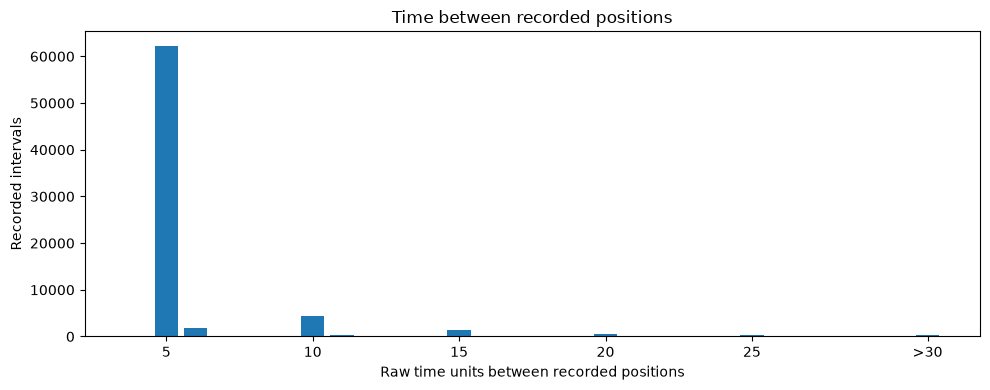

No unchanged samples would not prove players never stand still: the logging policy and precision are unconfirmed.


In [13]:
print("Sampling gaps and movement distances, using distinct unambiguous positions:")
steps.groupBy("actor_type").agg(
    F.count("*").alias("positive_time_intervals"),
    F.min("time_gap").alias("smallest_gap"),
    F.percentile_approx("time_gap", 0.5).alias("median_gap"),
    F.percentile_approx("time_gap", 0.95).alias("gap_95th_percentile"),
    F.max("time_gap").alias("largest_gap"),
    F.sum(F.when(F.col("time_gap") > 15, 1).otherwise(0)).alias("gaps_over_15"),
    F.sum(F.when(F.col("distance_xz") == 0, 1).otherwise(0)).alias("unchanged_xz_intervals"),
).show(truncate=False)

print("Ten largest sampling gaps; the line between their endpoints is not an observed route:")
step_columns = ["match_id", "user_id", "actor_type", "map_id", "previous_time", "timestamp_value",
                "time_gap", "distance_xz", "speed_per_raw_unit", "elevation_change"]
largest_gaps = steps.orderBy(F.desc("time_gap"), "match_id", "user_id")
largest_gaps.select(step_columns).show(10, truncate=False)
largest_gaps.select(step_columns).limit(30).toPandas().to_csv(evidence_folder / "largest_position_gaps.csv", index=False)

print("Histogram counts of sampling gaps, capped in the final >30 bin:")
gap_bins = steps.withColumn("gap_bin", F.when(F.col("time_gap") > 30, 31).otherwise(F.col("time_gap")))
gap_histogram = gap_bins.groupBy("gap_bin").count().orderBy("gap_bin").toPandas()
display(gap_histogram)
gap_histogram.to_csv(evidence_folder / "sampling_gap_histogram.csv", index=False)
plt.figure(figsize=(10, 4))
plt.bar(gap_histogram["gap_bin"], gap_histogram["count"])
plt.xticks([5, 10, 15, 20, 25, 31], ["5", "10", "15", "20", "25", ">30"])
plt.xlabel("Raw time units between recorded positions")
plt.ylabel("Recorded intervals")
plt.title("Time between recorded positions")
plt.tight_layout()
print("Chart of sampling gaps; >30 combines all larger gaps:")
plt.show()

movement_summary = steps.groupBy("actor_type").agg(
    F.count("*").alias("intervals"),
    F.percentile_approx("time_gap", 0.5).alias("median_gap"),
    F.max("time_gap").alias("maximum_gap"),
    F.sum(F.when(F.col("time_gap") > 15, 1).otherwise(0)).alias("gaps_over_15"),
    F.sum(F.when(F.col("distance_xz") == 0, 1).otherwise(0)).alias("unchanged_xz_intervals"),
)
facts["movement"] = {
    "conflicting_position_timestamps": conflicting_positions.count(),
    "distinct_positions": positions.count(),
    "positive_intervals": steps.count(),
    "sampling_by_actor": [row.asDict() for row in movement_summary.collect()],
}
print("No unchanged samples would not prove players never stand still: the logging policy and precision are unconfirmed.")

**What we found**

There are **no conflicting X/Y/Z positions for one actor at one timestamp** after the copied-file comparison. The remaining repeated movement samples agree exactly. After collapsing identical positions for this interval calculation, we have **72,849 distinct positions** and **71,607 positive-time intervals**.

The median gap is **5 raw time units** for both humans and bots. The largest observed gap is **302** for humans and **518** for bots. There are **1,361 human intervals** and **176 bot intervals** longer than the exploratory 15-unit threshold.

No positive-time interval has exactly unchanged X/Z. This does **not** prove every actor constantly moves or that the logger suppresses stationary samples: precision, jitter, and the logging policy are not established. It does mean a sample-count heatmap must not be called a measured time-spent heatmap without a separate justified method.

## 7. Inspect large jumps and apparent speeds

**What we are checking:** A large distance over a long missing interval is different from a large distance in a short interval. We do not know movement limits, so statistical extremes are review candidates, not confirmed errors.

**What we will print:** The largest distances, highest apparent speeds, and source records surrounding one example of each.

In [14]:
print("Ten largest X/Z distances between consecutive recorded positions:")
largest_distances = steps.orderBy(F.desc("distance_xz"), "match_id", "user_id")
largest_distances.select(step_columns).show(10, truncate=False)
print("Ten highest apparent speeds, in world units per raw time unit:")
fastest_steps = steps.orderBy(F.desc("speed_per_raw_unit"), "match_id", "user_id")
fastest_steps.select(step_columns).show(10, truncate=False)
fastest_steps.select(step_columns).limit(30).toPandas().to_csv(evidence_folder / "highest_apparent_speeds.csv", index=False)

review_examples = [
    ("Largest distance", largest_distances.first()),
    ("Highest apparent speed", fastest_steps.first()),
    ("Largest recording gap", largest_gaps.first()),
]
for description, example in review_examples:
    print("\nSource records around the example:", description)
    print("Match:", example["match_id"], "Actor:", example["user_id"])
    print("Gap:", example["time_gap"], "Distance:", example["distance_xz"], "Apparent speed:", example["speed_per_raw_unit"])
    one_copy_events.filter(
        (F.col("match_id") == example["match_id"])
        & (F.col("user_id") == example["user_id"])
        & F.col("timestamp_value").between(example["previous_time"] - 5, example["timestamp_value"] + 5)
    ).select("event", "timestamp_value", "x", "y", "z").orderBy("timestamp_value", "event").show(20, truncate=False)

facts["jump_review"] = {
    "largest_distance_xz": float(largest_distances.first()["distance_xz"]),
    "gap_for_largest_distance": int(largest_distances.first()["time_gap"]),
    "highest_apparent_speed": float(fastest_steps.first()["speed_per_raw_unit"]),
    "gap_for_highest_speed": int(fastest_steps.first()["time_gap"]),
    "largest_gap": int(largest_gaps.first()["time_gap"]),
}
print("The short tables are samples of the source rows; the gap and speed rankings use every eligible interval.")
print("No event has been labelled a teleport or cheating event, and no interval has been repaired.")

Ten largest X/Z distances between consecutive recorded positions:
+---------------------------------------------+------------------------------------+----------+-------------+-------------+---------------+--------+------------------+------------------+----------------+
|match_id                                     |user_id                             |actor_type|map_id       |previous_time|timestamp_value|time_gap|distance_xz       |speed_per_raw_unit|elevation_change|
+---------------------------------------------+------------------------------------+----------+-------------+-------------+---------------+--------+------------------+------------------+----------------+
|bca3ec7b-a11b-4e78-bb82-a92174e13fd2.nakama-0|94d042cb-a0f2-45f3-bdca-42fab73cfef5|human     |AmbroseValley|1770748386   |1770748411     |25      |63.571974926800486|2.5428789970720196|2.734085        |
|f3207c1c-1678-47c1-821e-09914e324d64.nakama-0|23f4ebd6-389f-4659-a135-f80b419475cc|human     |AmbroseValley|177098041

+---------------------------------------------+------------------------------------+----------+-------------+-------------+---------------+--------+------------------+------------------+----------------+
|match_id                                     |user_id                             |actor_type|map_id       |previous_time|timestamp_value|time_gap|distance_xz       |speed_per_raw_unit|elevation_change|
+---------------------------------------------+------------------------------------+----------+-------------+-------------+---------------+--------+------------------+------------------+----------------+
|f3207c1c-1678-47c1-821e-09914e324d64.nakama-0|23f4ebd6-389f-4659-a135-f80b419475cc|human     |AmbroseValley|1770980413   |1770980418     |5       |63.26038815075651 |12.652077630151302|3.5325851       |
|9dee72b8-a9c8-42b8-8cc2-20961c16758a.nakama-0|a0738c7c-612e-45c9-b24d-057115642057|human     |AmbroseValley|1770722647   |1770722652     |5       |62.56525889895885 |12.51305177979177


Source records around the example: Largest distance
Match: bca3ec7b-a11b-4e78-bb82-a92174e13fd2.nakama-0 Actor: 94d042cb-a0f2-45f3-bdca-42fab73cfef5
Gap: 25 Distance: 63.571974926800486 Apparent speed: 2.5428789970720196
+--------+---------------+----------+----------+---------+
|event   |timestamp_value|x         |y         |z        |
+--------+---------------+----------+----------+---------+
|Position|1770748381     |2.8357968 |113.859146|51.95244 |
|Position|1770748386     |-15.663022|111.00531 |12.752481|
|BotKill |1770748403     |-15.198112|111.00531 |12.891978|
|Position|1770748411     |11.455259 |113.739395|70.25026 |
|Position|1770748416     |16.275354 |112.698654|79.0661  |
+--------+---------------+----------+----------+---------+


Source records around the example: Highest apparent speed
Match: f3207c1c-1678-47c1-821e-09914e324d64.nakama-0 Actor: 23f4ebd6-389f-4659-a135-f80b419475cc
Gap: 5 Distance: 63.26038815075651 Apparent speed: 12.652077630151302
+--------+----------

+-----------+---------------+----------+--------+----------+
|event      |timestamp_value|x         |y       |z         |
+-----------+---------------+----------+--------+----------+
|BotPosition|1770726881     |99.84574  |131.025 |-273.94904|
|BotPosition|1770726886     |107.56218 |131.025 |-278.45407|
|BotPosition|1770727404     |115.13365 |131.0526|-277.1988 |
|BotPosition|1770727409     |107.600784|131.025 |-278.52228|
+-----------+---------------+----------+--------+----------+



The short tables are samples of the source rows; the gap and speed rankings use every eligible interval.
No event has been labelled a teleport or cheating event, and no interval has been repaired.


**What we found**

The largest observed X/Z displacement is approximately **63.57 world units over 25 raw time units**. The highest apparent speed comes from a different interval: approximately **63.26 units over 5 raw time units**, or **12.65 world units per raw time unit**.

The longest gap is especially important: bot `1441` in match `92b5d106…` has **518 raw time units** between positions whose endpoints are only about **7.67 world units apart**. It could have remained near the location or travelled elsewhere and returned; the missing interval does not tell us which.

We inspected source rows around these examples. We did **not** establish a teleport, an impossible speed, or a corrupted position. Allowed speeds, world-distance units, and the producer's intended time units are not documented well enough for those labels. Playback should expose large gaps, and an occupancy analysis must not assume the actor remained at the last location throughout the gap.

## 8. Independently check three representative matches

**What we are checking:** A few concrete matches help us verify that aggregate metrics match the supplied rows. We compare Spark counts with a separate PyArrow/Python count and inspect example source events.

**What we will print:** One single-ID combat match, the match with the most recorded IDs, and the copied-file match; raw and file-copy-excluded counts are shown separately.

In [15]:
match_metrics = events.groupBy("match_id").agg(
    F.count("*").alias("event_rows"),
    F.countDistinct("user_id").alias("recorded_ids"),
    F.countDistinct(F.when(F.col("actor_type") == "human", F.col("user_id"))).alias("human_ids"),
    F.countDistinct(F.when(F.col("actor_type") == "bot", F.col("user_id"))).alias("bot_ids"),
    F.sum(F.when(F.col("event").isin("Kill", "BotKill"), 1).otherwise(0)).alias("kill_label_rows"),
    F.sum(F.when(F.col("event") == "Loot", 1).otherwise(0)).alias("loot_rows"),
).cache()
first_single_match = match_metrics.filter(F.col("recorded_ids") == 1).orderBy(
    F.desc("kill_label_rows"), F.desc("loot_rows"), "match_id"
).first()["match_id"]
most_ids_match = match_metrics.orderBy(F.desc("recorded_ids"), "match_id").first()["match_id"]
copied_file_match = Path(identical_files.iloc[0]["source_file"]).name.split("_", 1)[1]
chosen_matches = [
    ("One recorded ID with many kill labels", first_single_match),
    ("Most recorded IDs", most_ids_match),
    ("Byte-identical file appears in two folders", copied_file_match),
]
print("The three selected matches and their raw-source metrics:")
match_metrics.filter(F.col("match_id").isin([match for reason, match in chosen_matches])).show(truncate=False)

comparison_rows = []
for reason, match_id in chosen_matches:
    raw_counter = Counter()
    file_copy_counter = Counter()
    direct_actor_ids = set()
    for file_path in parquet_files:
        if file_path.name.split("_", 1)[1] != match_id:
            continue
        source_records = parquet.read_table(file_path).to_pylist()
        relative_path = str(file_path.relative_to(data_folder))
        for record in source_records:
            event_name = record["event"].decode("utf-8")
            raw_counter[event_name] += 1
            direct_actor_ids.add(record["user_id"])
            if relative_path in first_file_paths:
                file_copy_counter[event_name] += 1

    spark_raw_counter = {}
    for row in events.filter(F.col("match_id") == match_id).groupBy("event").count().collect():
        spark_raw_counter[row["event"]] = row["count"]
    spark_file_counter = {}
    for row in one_copy_events.filter(F.col("match_id") == match_id).groupBy("event").count().collect():
        spark_file_counter[row["event"]] = row["count"]
    assert dict(raw_counter) == spark_raw_counter, match_id
    assert dict(file_copy_counter) == spark_file_counter, match_id
    assert len(direct_actor_ids) == match_summary.filter(F.col("match_id") == match_id).first()["recorded_actors"]

    comparison_rows.append({
        "selection_reason": reason, "match_id": match_id,
        "recorded_ids": len(direct_actor_ids),
        "all_source_rows": sum(raw_counter.values()),
        "one_copy_per_file_rows": sum(file_copy_counter.values()),
        "raw_kill_label_rows": raw_counter["Kill"] + raw_counter["BotKill"],
        "raw_loot_rows": raw_counter["Loot"],
        "independent_count_agrees": True,
    })
print("Independent PyArrow/Python counts compared with Spark for every event label in the selected matches:")
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)
comparison_table.to_csv(evidence_folder / "representative_match_checks.csv", index=False)
facts["representative_matches"] = comparison_rows

The three selected matches and their raw-source metrics:
+---------------------------------------------+----------+------------+---------+-------+---------------+---------+
|match_id                                     |event_rows|recorded_ids|human_ids|bot_ids|kill_label_rows|loot_rows|
+---------------------------------------------+----------+------------+---------+-------+---------------+---------+
|ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0|359       |7           |1        |6      |11             |38       |
|fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0|1015      |16          |1        |15     |5              |7        |
|b3550292-8f80-493a-a422-95c4e70f0a5e.nakama-0|217       |1           |1        |0      |38             |43       |
+---------------------------------------------+----------+------------+---------+-------+---------------+---------+



Independent PyArrow/Python counts compared with Spark for every event label in the selected matches:


,selection_reason,match_id,recorded_ids,all_source_rows,one_copy_per_file_rows,raw_kill_label_rows,raw_loot_rows,independent_count_agrees
0,One recorded ID with many kill labels,b3550292-8f80-493a-a422-95c4e70f0a5e.nakama-0,1,217,217,38,43,True
1,Most recorded IDs,fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0,16,1015,1015,5,7,True
2,Byte-identical file appears in two folders,ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0,7,359,271,11,38,True


In [16]:
print("Event-label counts for the single-ID combat example:")
events.filter(F.col("match_id") == first_single_match).groupBy("event").count().orderBy("event").show()
print("Human/bot event counts for the match with the most recorded IDs:")
events.filter(F.col("match_id") == most_ids_match).groupBy("actor_type", "event").count().orderBy(
    "actor_type", "event"
).show(20)
print("Raw source files and counts for the copied-file example:")
events.filter(F.col("match_id") == copied_file_match).groupBy("source_file").count().orderBy("source_file").show(truncate=False)
print("These are row-count spot checks. They do not verify the real-world meaning of each combat label.")

Event-label counts for the single-ID combat example:
+--------+-----+
|   event|count|
+--------+-----+
| BotKill|   38|
|    Loot|   43|
|Position|  136|
+--------+-----+

Human/bot event counts for the match with the most recorded IDs:


+----------+-----------+-----+
|actor_type|      event|count|
+----------+-----------+-----+
|       bot|    BotKill|    5|
|       bot|  BotKilled|    7|
|       bot|BotPosition|  951|
|       bot|       Loot|    7|
|       bot|   Position|   27|
|     human|  BotKilled|    1|
|     human|   Position|   17|
+----------+-----------+-----+

Raw source files and counts for the copied-file example:
+----------------------------------------------------------------------------------------------+-----+
|source_file                                                                                   |count|
+----------------------------------------------------------------------------------------------+-----+
|February_10/cfa03e9f-81f6-41ef-a0fa-30c7e830f4ed_ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0|88   |
|February_11/1436_ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0                                |14   |
|February_11/1440_ac049b28-8116-4ff1-9e60-4be0537b8cc9.nakama-0                       

**What we found**

Independent PyArrow/Python counters agreed with Spark for **every event label** in all three selected matches, both before and after the copied-file comparison.

- `b3550292…`: **217 rows**, one recorded human ID, **38 BotKill** labels, and **43 Loot** labels. No separate opponent ID is required for those labels to appear under the recorded human.
- `fbbc5d02…`: **1,015 rows**, **16 recorded IDs** comprising one human and 15 bots, five kill-labelled rows, and seven loot rows.
- `ac049b28…`: **359 supplied rows**, or **271** after retaining one identical file copy; seven recorded IDs. This verifies that the import policy can change a match's metrics.

These checks confirm counting consistency and source interpretation mechanics. They do not certify every combat label as a unique kill or each loot row as one distinct item.

## 9. Confirm map assets and coordinate handling

**What we are checking:** Native image dimensions differ from the README, and world Y is elevation. We need bounds checks and a correctly transformed example, not an assumption that every image is a 1024 square.

**What we will print:** Actual asset dimensions, map coordinate limits, out-of-bounds counts, and the README example calculation.

In [17]:
map_settings = spark.createDataFrame([
    ("AmbroseValley", 900.0, -370.0, -473.0),
    ("GrandRift", 581.0, -290.0, -290.0),
    ("Lockdown", 1000.0, -500.0, -500.0),
], ["map_id", "world_scale", "origin_x", "origin_z"])
map_files = {
    "AmbroseValley": data_folder / "minimaps/AmbroseValley_Minimap.png",
    "GrandRift": data_folder / "minimaps/GrandRift_Minimap.png",
    "Lockdown": data_folder / "minimaps/Lockdown_Minimap.jpg",
}
image_details = []
for map_id, image_path in map_files.items():
    with Image.open(image_path) as image:
        image_details.append({"map_id": map_id, "width": image.width, "height": image.height})
print("Actual minimap image dimensions:")
display(pd.DataFrame(image_details))

mapped_events = events.join(map_settings, on="map_id", how="left")
mapped_events = mapped_events.withColumn("u", (F.col("x") - F.col("origin_x")) / F.col("world_scale"))
mapped_events = mapped_events.withColumn("v", (F.col("z") - F.col("origin_z")) / F.col("world_scale"))
mapped_events = mapped_events.withColumn("inside_map", F.col("u").between(0, 1) & F.col("v").between(0, 1))
print("Normalized X/Z ranges, elevation ranges, and bounds failures for every map:")
mapped_events.groupBy("map_id").agg(
    F.min("u").alias("minimum_u"), F.max("u").alias("maximum_u"),
    F.min("v").alias("minimum_v"), F.max("v").alias("maximum_v"),
    F.min("y").alias("minimum_elevation"), F.max("y").alias("maximum_elevation"),
    F.sum(F.when(~F.col("inside_map"), 1).otherwise(0)).alias("outside_map_rows"),
).orderBy("map_id").show(truncate=False)

example_pixel_x = ((-301.45 + 370) / 900) * 1024
example_pixel_y = (1 - ((-355.55 + 473) / 900)) * 1024
print("README example on a 1024-pixel reference image:", example_pixel_x, example_pixel_y)
assert abs(example_pixel_x - 78) < 1 and abs(example_pixel_y - 890) < 1
facts["maps"] = {
    "image_dimensions": image_details,
    "outside_map_rows": mapped_events.filter(~F.col("inside_map")).count(),
    "missing_map_config_rows": mapped_events.filter(F.col("world_scale").isNull()).count(),
}
print("A bounds check and the README example validate the transform's mechanics, not every intended gameplay boundary.")

Actual minimap image dimensions:


,map_id,width,height
0,AmbroseValley,4320,4320
1,GrandRift,2160,2158
2,Lockdown,9000,9000


Normalized X/Z ranges, elevation ranges, and bounds failures for every map:


+-------------+-------------------+------------------+-------------------+------------------+-----------------+-----------------+----------------+
|map_id       |minimum_u          |maximum_u         |minimum_v          |maximum_v         |minimum_elevation|maximum_elevation|outside_map_rows|
+-------------+-------------------+------------------+-------------------+------------------+-----------------+-----------------+----------------+
|AmbroseValley|0.05003668891059028|0.7464303249782986|0.10332539876302084|0.9263974677191841|100.0            |162.6662         |0               |
|GrandRift    |0.11032044087342674|0.9408199027975742|0.16522411142897483|0.7919324392295746|8.138657         |46.85613         |0               |
|Lockdown     |0.0933704833984375 |0.8483560791015625|0.2148953857421875 |0.8292378540039063|32.58429         |70.554115        |0               |
+-------------+-------------------+------------------+-------------------+------------------+-----------------+-------

A bounds check and the README example validate the transform's mechanics, not every intended gameplay boundary.


Map of the longest-gap endpoints; no connecting route is claimed:


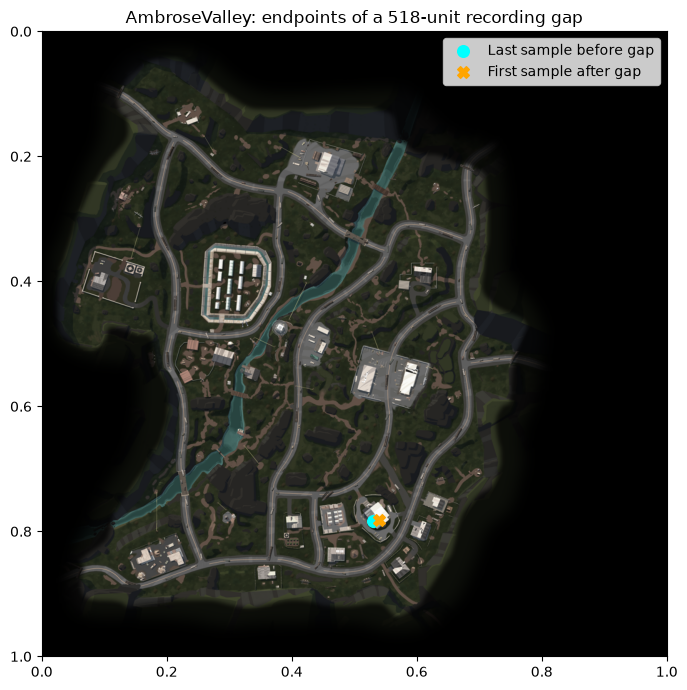

In [18]:
# A long recording gap: show its endpoints, not an invented route between them.
gap_example = largest_gaps.first()
gap_map = gap_example["map_id"]
gap_settings = map_settings.filter(F.col("map_id") == gap_map).first()
start_u = (gap_example["previous_x"] - gap_settings["origin_x"]) / gap_settings["world_scale"]
start_v = (gap_example["previous_z"] - gap_settings["origin_z"]) / gap_settings["world_scale"]
end_u = (gap_example["x"] - gap_settings["origin_x"]) / gap_settings["world_scale"]
end_v = (gap_example["z"] - gap_settings["origin_z"]) / gap_settings["world_scale"]
figure, axis = plt.subplots(figsize=(7, 7))
with Image.open(map_files[gap_map]) as image:
    image.thumbnail((1000, 1000))
    axis.imshow(image, extent=(0, 1, 1, 0))
axis.scatter([start_u], [1 - start_v], s=70, color="cyan", label="Last sample before gap")
axis.scatter([end_u], [1 - end_v], s=70, marker="X", color="orange", label="First sample after gap")
axis.set_xlim(0, 1)
axis.set_ylim(1, 0)
axis.set_title(f"{gap_map}: endpoints of a {gap_example['time_gap']}-unit recording gap")
axis.legend()
plt.tight_layout()
print("Map of the longest-gap endpoints; no connecting route is claimed:")
plt.show()

**What we found**

The actual image sizes are **4320×4320**, **2160×2158**, and **9000×9000** for Ambrose Valley, Grand Rift, and Lockdown respectively. They are not all 1024×1024, and Grand Rift is not perfectly square.

All supplied coordinates fit the documented normalized map bounds, and no map configuration is missing. The README example produces approximately **(78, 890)** on its 1024-pixel reference image. Use world X/Z, retain Y as elevation, apply the vertical flip, and scale each axis using the rendered image dimensions.

The example map intentionally shows only the endpoints of the longest recording gap. A line between them would not show a measured route. Passing a normalized bounds check does not establish playable terrain boundaries or eliminate the need to inspect visual alignment.

## 10. Recheck the scope of the kill-attribution investigation

**What we are checking:** The 82 pairings and the 105 other death moments must not be mixed. We preserve all exact-time pairs before checking later positions and compare their coordinates separately.

**What we will print:** Unfiltered pair counts, human/bot combinations, late-position exceptions, and a separate all-death-moment summary. This is not a new claim that killer identities are verified.

In [19]:
events.createOrReplaceTempView("player_events")
combat_audit_sql = (project_folder / "queries" / "audit_simultaneous_kill_death.sql").read_text()
print("Exact SQL used for the unfiltered same-match, same-time, distinct-ID audit:")
print(combat_audit_sql)
combat_pairs = spark.sql(combat_audit_sql).cache()
print("All candidate pairings before filtering on movement endings:")
combat_pairs.groupBy("movement_result").count().show(truncate=False)
print("Every ID-type combination found; an absent human-to-human row does not mean the query excluded it:")
combat_pairs.groupBy("possible_killer_type", "possible_victim_type").count().show()

print("Plain Kill and Killed records, including their same-ID coincidences:")
events.filter(F.col("event").isin("Kill", "Killed")).select(
    "match_id", "user_id", "event", "timestamp_value"
).orderBy("match_id", "event").show(truncate=False)

Exact SQL used for the unfiltered same-match, same-time, distinct-ID audit:
-- Spark SQL against the notebook's decoded player_events view.
-- Keep every same-time pair. Movement endings are results, not filters.
WITH movement_endings AS (
    SELECT
        match_id,
        user_id,
        MAX(timestamp_value) AS last_position_time
    FROM player_events
    WHERE event IN ('Position', 'BotPosition')
    GROUP BY match_id, user_id
),
simultaneous_pairs AS (
    SELECT DISTINCT
        killer.match_id,
        killer.map_id,
        killer.timestamp_value AS event_timestamp,
        killer.user_id AS possible_killer_id,
        killer.actor_type AS possible_killer_type,
        killer.event AS kill_event,
        victim.user_id AS possible_victim_id,
        victim.actor_type AS possible_victim_type,
        victim.event AS death_event
    FROM player_events AS killer
    JOIN player_events AS victim
        ON victim.match_id = killer.match_id
        AND victim.timestamp_value = ki

All candidate pairings before filtering on movement endings:


+-----------------------------+-----+
|movement_result              |count|
+-----------------------------+-----+
|victim_has_no_later_positions|80   |
|both_have_later_positions    |2    |
+-----------------------------+-----+

Every ID-type combination found; an absent human-to-human row does not mean the query excluded it:
+--------------------+--------------------+-----+
|possible_killer_type|possible_victim_type|count|
+--------------------+--------------------+-----+
|               human|                 bot|   28|
|                 bot|                 bot|   49|
|                 bot|               human|    5|
+--------------------+--------------------+-----+

Plain Kill and Killed records, including their same-ID coincidences:
+---------------------------------------------+------------------------------------+------+---------------+
|match_id                                     |user_id                             |event |timestamp_value|
+-----------------------------------

In [20]:
# Compare any later position with the coordinates recorded on the death label.
death_points = events.filter(F.col("event").isin("Killed", "BotKilled")).select(
    "match_id", F.col("timestamp_value").alias("death_time"),
    F.col("user_id").alias("victim_id"), F.col("actor_type").alias("victim_type"),
    F.col("event").alias("death_event"),
    F.col("x").alias("death_x"), F.col("y").alias("death_y"), F.col("z").alias("death_z"),
).distinct()
# Collapse exact repeated position payloads for this follow-up's sample count only.
followup_positions = events.filter(F.col("event").isin("Position", "BotPosition")).select(
    F.col("match_id").alias("position_match"), F.col("user_id").alias("position_user"),
    F.col("timestamp_value").alias("position_time"),
    F.col("x").alias("position_x"), F.col("y").alias("position_y"), F.col("z").alias("position_z"),
).distinct()
later_positions = death_points.join(
    followup_positions,
    (F.col("match_id") == F.col("position_match"))
    & (F.col("victim_id") == F.col("position_user"))
    & (F.col("position_time") > F.col("death_time")), how="inner",
)
delta_x = F.col("position_x") - F.col("death_x")
delta_y = F.col("position_y") - F.col("death_y")
delta_z = F.col("position_z") - F.col("death_z")
later_positions = later_positions.withColumn("distance_xz", F.sqrt(delta_x * delta_x + delta_z * delta_z))
later_positions = later_positions.withColumn("distance_xyz", F.sqrt(delta_x * delta_x + delta_y * delta_y + delta_z * delta_z))
later_positions = later_positions.withColumn("time_offset", F.col("position_time") - F.col("death_time"))

followup_summary = later_positions.groupBy("match_id", "death_time", "victim_id", "death_event").agg(
    F.count("*").alias("distinct_later_samples"),
    F.max("time_offset").alias("last_followup_offset"),
    F.max("distance_xyz").alias("largest_distance_xyz"),
    F.max("distance_xz").alias("largest_distance_xz"),
)
all_death_moments = death_points.select("match_id", "death_time", "victim_id", "victim_type", "death_event").distinct()
all_death_moments = all_death_moments.join(
    followup_summary, on=["match_id", "death_time", "victim_id", "death_event"], how="left"
).fillna({"distinct_later_samples": 0, "largest_distance_xyz": 0.0, "largest_distance_xz": 0.0})
all_death_moments = all_death_moments.withColumn("followup_result",
    F.when(F.col("distinct_later_samples") == 0, "no_later_positions")
    .when(F.col("largest_distance_xyz") == 0, "later_positions_at_death_location")
    .otherwise("changed_coordinates_after_death")
).cache()
print("All combat-death moments, without requiring an identified opposing ID:")
all_death_moments.groupBy("followup_result").count().show(truncate=False)

pair_death_moments = all_death_moments.withColumnRenamed("death_time", "event_timestamp").withColumnRenamed("victim_id", "possible_victim_id")
paired_followups = combat_pairs.join(
    pair_death_moments.select("match_id", "event_timestamp", "possible_victim_id", "death_event", "followup_result"),
    on=["match_id", "event_timestamp", "possible_victim_id", "death_event"], how="left",
)
print("Only the matched pairings, with no pre-filter on later movement:")
paired_followups.groupBy("followup_result").count().show(truncate=False)
print("Distinct death moments represented in the pair list; pairings and death moments are different counting units:")
combat_pairs.select("match_id", "event_timestamp", "possible_victim_id", "death_event").distinct().agg(F.count("*").alias("matched_death_moments")).show()

All combat-death moments, without requiring an identified opposing ID:


+---------------------------------+-----+
|followup_result                  |count|
+---------------------------------+-----+
|no_later_positions               |550  |
|later_positions_at_death_location|45   |
|changed_coordinates_after_death  |105  |
+---------------------------------+-----+

Only the matched pairings, with no pre-filter on later movement:
+---------------------------------+-----+
|followup_result                  |count|
+---------------------------------+-----+
|no_later_positions               |80   |
|later_positions_at_death_location|2    |
+---------------------------------+-----+

Distinct death moments represented in the pair list; pairings and death moments are different counting units:


+---------------------+
|matched_death_moments|
+---------------------+
|                   80|
+---------------------+



In [21]:
changed_death_moments = all_death_moments.filter(F.col("largest_distance_xyz") > 0)
print("How large and how late the changed-coordinate follow-ups are, across all such death moments:")
changed_severity = changed_death_moments.agg(
    F.count("*").alias("changed_coordinate_death_moments"),
    F.max("last_followup_offset").alias("maximum_late_offset"),
    F.max("distinct_later_samples").alias("maximum_distinct_later_samples"),
    F.max("largest_distance_xz").alias("maximum_xz_change"),
    F.percentile_approx("largest_distance_xz", 0.5).alias("median_xz_change"),
    F.max("largest_distance_xyz").alias("maximum_xyz_change"),
)
changed_severity.show(truncate=False)
changed_death_moments.orderBy(F.desc("largest_distance_xyz")).limit(15).toPandas().to_csv(
    evidence_folder / "largest_post_death_coordinate_changes.csv", index=False
)

facts["combat_scopes"] = {
    "unfiltered_candidate_pairs": combat_pairs.count(),
    "matched_death_moments": combat_pairs.select("match_id", "event_timestamp", "possible_victim_id", "death_event").distinct().count(),
    "human_human_pairs": combat_pairs.filter((F.col("possible_killer_type") == "human") & (F.col("possible_victim_type") == "human")).count(),
    "paired_followup_results": [row.asDict() for row in paired_followups.groupBy("followup_result").count().collect()],
    "all_death_moments": all_death_moments.count(),
    "all_death_followup_results": [row.asDict() for row in all_death_moments.groupBy("followup_result").count().collect()],
    "changed_followup_severity": changed_severity.first().asDict(),
}
print("These are observations of recorded data. Small final updates do not prove respawning or continued live gameplay.")
print("The 105 broader cases are not exceptions inside the matched 82 pairings; their input scopes differ.")

How large and how late the changed-coordinate follow-ups are, across all such death moments:
+--------------------------------+-------------------+------------------------------+-----------------+-------------------+------------------+
|changed_coordinate_death_moments|maximum_late_offset|maximum_distinct_later_samples|maximum_xz_change|median_xz_change   |maximum_xyz_change|
+--------------------------------+-------------------+------------------------------+-----------------+-------------------+------------------+
|105                             |6                  |2                             |1.648450950820789|0.16132779317641596|1.6491546517208016|
+--------------------------------+-------------------+------------------------------+-----------------+-------------------+------------------+



These are observations of recorded data. Small final updates do not prove respawning or continued live gameplay.
The 105 broader cases are not exceptions inside the matched 82 pairings; their input scopes differ.


**What we found**

The earlier investigation reproduces under this independent load. Keep its two scopes separate:

| Scope | Findings |
|---|---|
| All distinct-ID same-match same-time candidate pairs | **82 pairings**: 80 with no later victim positions, two with final positions exactly at the death location, none with changed victim coordinates afterward |
| All recorded combat-death ID/time/label moments, with or without an identified opponent | **700 moments**: 550 with no later positions, 45 with later positions at the death location, **105 with changed coordinates afterward** |

**82 pairings represent 80 distinct death moments**, because a death moment can match more than one potential killer. Pair counts and death-moment counts cannot be added or subtracted as if they were the same unit.

The 105 broader cases do not qualify for the paired check. Their follow-ups extend at most **6 raw time units**, contain at most **two distinct later samples**, and have a median maximum X/Z change of about **0.16 world units** and an overall maximum of about **1.65**. These are measured update differences, not proof of respawning, continued live play, or a particular logging cause.

There are **zero two-human exact-time candidate pairs**. The three `Kill`/`Killed` cases each put both labels under the same human ID. That does not identify a second human or prove a self-kill.

**This remains an exploratory investigation.** It does not establish a universal killer/victim identification rule, even though particular candidate associations have strong supporting evidence.

**Current decision:** kill labels are credited to the recorded actor ID, whether human or bot, including bot-versus-bot combat. This resolves the event-credit convention for the project; exact opponent-ID inference is not required for counting or plotting these events.

## 11. Record what these data cannot answer

**What we are checking:** A good tool must not invent unrecorded facts. We distinguish required data handling from missing information and uncertain producer behavior.

**What we will print:** The complete source field and event lists, plus the scope of the evidence saved by this pass.

In [22]:
print("Complete source columns:")
print(raw_events.columns)
print("Complete event-label inventory and recorded actor-type counts:")
events.groupBy("event", "actor_type").count().orderBy("event", "actor_type").show(20)
print("No explicit killer/victim relationship, item ID, extraction outcome, or storm boundary is supplied.")
print("No verified match-start/end marker or stationary-player logging policy is supplied.")
print("February 14 is a partial day according to the README; raw day totals are not a normalized engagement trend.")

facts["event_counts"] = {row["event"]: row["count"] for row in events.groupBy("event").count().collect()}
facts["actor_counts"] = {row["actor_type"]: row["ids"] for row in events.groupBy("actor_type").agg(F.countDistinct("user_id").alias("ids")).collect()}
summary_path = evidence_folder / "pass_summary.json"
summary_path.write_text(json.dumps(facts, indent=2, default=str) + "\n")
print("Machine-readable evidence summary saved to:", summary_path)
print("Detailed findings are written in plain English after each section and consolidated in docs/DATA_NUANCES.md.")

Complete source columns:
['user_id', 'match_id', 'map_id', 'x', 'y', 'z', 'ts', 'event']
Complete event-label inventory and recorded actor-type counts:
+-------------+----------+-----+
|        event|actor_type|count|
+-------------+----------+-----+
|      BotKill|       bot|  183|
|      BotKill|     human| 2232|
|    BotKilled|       bot|  297|
|    BotKilled|     human|  403|
|  BotPosition|       bot|21712|
|         Kill|     human|    3|
|       Killed|     human|    3|
|KilledByStorm|     human|   39|
|         Loot|       bot|  115|
|         Loot|     human|12770|
|     Position|       bot|  636|
|     Position|     human|50711|
+-------------+----------+-----+

No explicit killer/victim relationship, item ID, extraction outcome, or storm boundary is supplied.
No verified match-start/end marker or stationary-player logging policy is supplied.
February 14 is a partial day according to the README; raw day totals are not a normalized engagement trend.


Machine-readable evidence summary saved to: /Users/mskbaruah/Documents/ChatGPT/LILA games/docs/analysis/focused_final_pass/pass_summary.json
Detailed findings are written in plain English after each section and consolidated in docs/DATA_NUANCES.md.


**What we found**

The eight source columns and eight event labels contain no explicit killer/victim link, item identity, item value, extraction outcome, storm geometry, or verified match-start/end marker. These absences limit what the tool can honestly calculate or reconstruct.

Daily comparisons also need care: February 14 is explicitly a partial day. Low sample density does not by itself establish that an area is ignored, that a player stood still, or that an area is playable.

The new pass found no failed independent match counts, unreadable files, malformed decoded labels, nonfinite positions, out-of-bounds coordinates, or conflicting same-time movement coordinates. Its main additional value is quantifying the import-policy effects, separating remaining within-recording repetition from copied files, inspecting the movement extremes, and stating the unresolved semantics clearly.

The comprehensive attention-point register is `docs/DATA_NUANCES.md`. Measured facts are saved in `rough work/analysis/focused_final_pass/pass_summary.json`; detailed evidence tables are next to it.

**Current decisions:** one `Loot` row counts as one looted item; plot all supplied recordings, including the 743 matches with one recorded ID. Neither issue blocks the project.

## Current project interpretation after the executive decisions

**The original four concerns and four of the five additional concerns have handling decisions.** The only remaining undecided data-handling question from those lists is how to count repeated combat rows.

| Observation | Current handling |
|---|---|
| Timestamps declared as milliseconds | Treat the stored integers as seconds; all 796 recorded spans are plausible |
| Combat labels under human and bot IDs | Credit kill events to the recorded actor, including bot-versus-bot cases |
| Repeated Loot rows | Count each row as one item |
| Matches with one recorded ID | Plot the supplied recordings |
| One whole 88-row file copied into two dates | Keep the February 10 copy; exclude the February 11 copy from processed data |
| 34 extra BotKill rows and two extra BotKilled rows inside retained files | Counting rule still undecided; see actual examples after section 4 |
| Position gaps up to 518 seconds | Advance directly to the next distinct recorded timestamp; process all simultaneous rows together |
| 105 death-labelled cases with small later coordinate changes | Plot the positions as supplied, retaining the death event; do not infer survival or respawn |
| 436 raw-source rows with a UTC date before their folder date | Put each processed record in its timestamp's date partition and use that date for filtering; UTC is the working convention |

Timestamp-step playback does not wait through an unsampled interval or invent intermediate positions. A timestamp with multiple actors/events is one simultaneous step. The original recorded times remain visible so a large gap can still be recognized.

**Final project-document reminder:** explain the observed nuances and how each was handled. Explicitly note that positions after death labels are plotted unchanged. These are approved rules for implementation; the sample UI and source files were not rewritten by this notebook documentation update.

The 17 report entries are an evidence register, not 17 open uncertainties. Image dimensions, byte decoding, sorting, event primary keys, and match-scoped bot IDs have known engineering solutions.

Full current decisions: `docs/PRODUCT_BRIEF.md`. Working decision log: [Data nuances and attention points](../../docs/DATA_NUANCES.md). Full seconds check: `rough work/analysis/focused_final_pass/match_seconds_validation.csv`. Repeated-combat evidence: `rough work/analysis/focused_final_pass/repeated_combat_payloads.csv`.

In [23]:
# spark.stop()